# 2. Forecast accuracy

`python -m src.forecast` fits one Prophet model per SKU (500 models) on everything except the last 90 days, then forecasts those 90 days. Each forecast is compared with a simple baseline: sales on the same weekday of the last training week.

**Metric:** WAPE = total absolute error ÷ total actual units. It's the retail standard and, unlike MAPE, isn't distorted by low-volume days.

In [1]:
import sys
sys.path.insert(0, '..')

import matplotlib.pyplot as plt
import pandas as pd

from src.config import PROCESSED
plt.rcParams['figure.dpi'] = 110
from src.metrics import wape

results = pd.read_csv(PROCESSED / 'forecast_results.csv', parse_dates=['date'])
metrics = pd.read_csv(PROCESSED / 'forecast_metrics.csv')
print(f"Overall WAPE: Prophet {wape(results.actual, results.prophet):.1f}%, baseline {wape(results.actual, results.baseline):.1f}%")
print(f"Prophet is more accurate on {(metrics.wape < metrics.baseline_wape).sum()} of {len(metrics)} SKUs")
metrics[['wape', 'mape', 'bias', 'baseline_wape']].describe().round(1)

Overall WAPE: Prophet 11.6%, baseline 21.3%
Prophet is more accurate on 500 of 500 SKUs


,wape,mape,bias,baseline_wape
count,500.0,500.0,500.0,500.0
mean,12.9,14.2,1.0,22.8
std,3.2,4.0,1.1,4.7
min,6.9,7.1,-2.0,14.7
25%,10.5,11.1,0.2,19.2
50%,12.2,13.2,0.9,22.0
75%,14.7,16.3,1.7,25.2
max,24.3,31.3,5.2,42.4


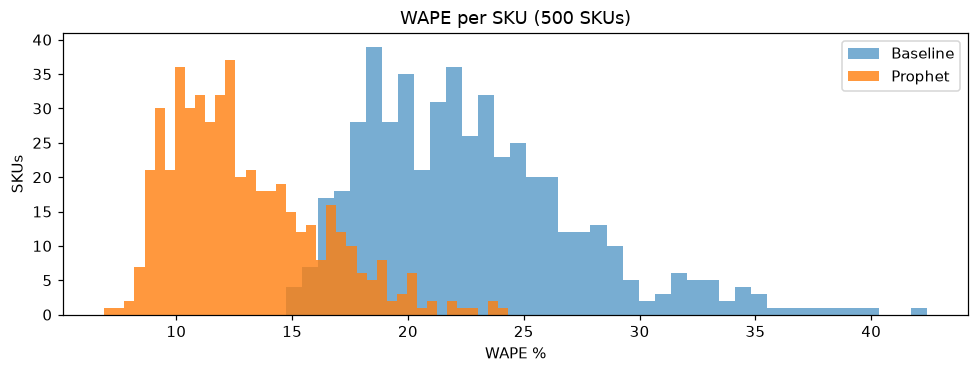

In [2]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(metrics.baseline_wape, bins=40, alpha=0.6, label='Baseline')
ax.hist(metrics.wape, bins=40, alpha=0.8, label='Prophet')
ax.set(title='WAPE per SKU (500 SKUs)', xlabel='WAPE %', ylabel='SKUs'); ax.legend(); plt.tight_layout()

Low-volume SKUs have the highest percentage error, because day-to-day noise is large relative to their sales:

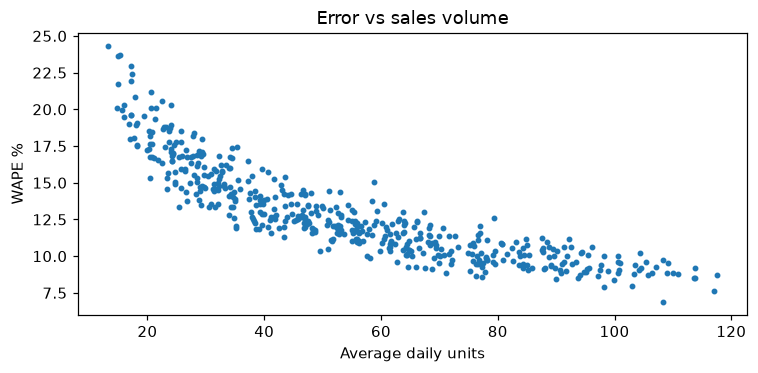

In [3]:
volume = results.groupby(['store', 'item']).actual.mean().rename('avg_daily_units').reset_index()
m = metrics.merge(volume)
ax = m.plot.scatter('avg_daily_units', 'wape', s=8, figsize=(7, 3.5), title='Error vs sales volume')
ax.set(xlabel='Average daily units', ylabel='WAPE %'); plt.tight_layout()

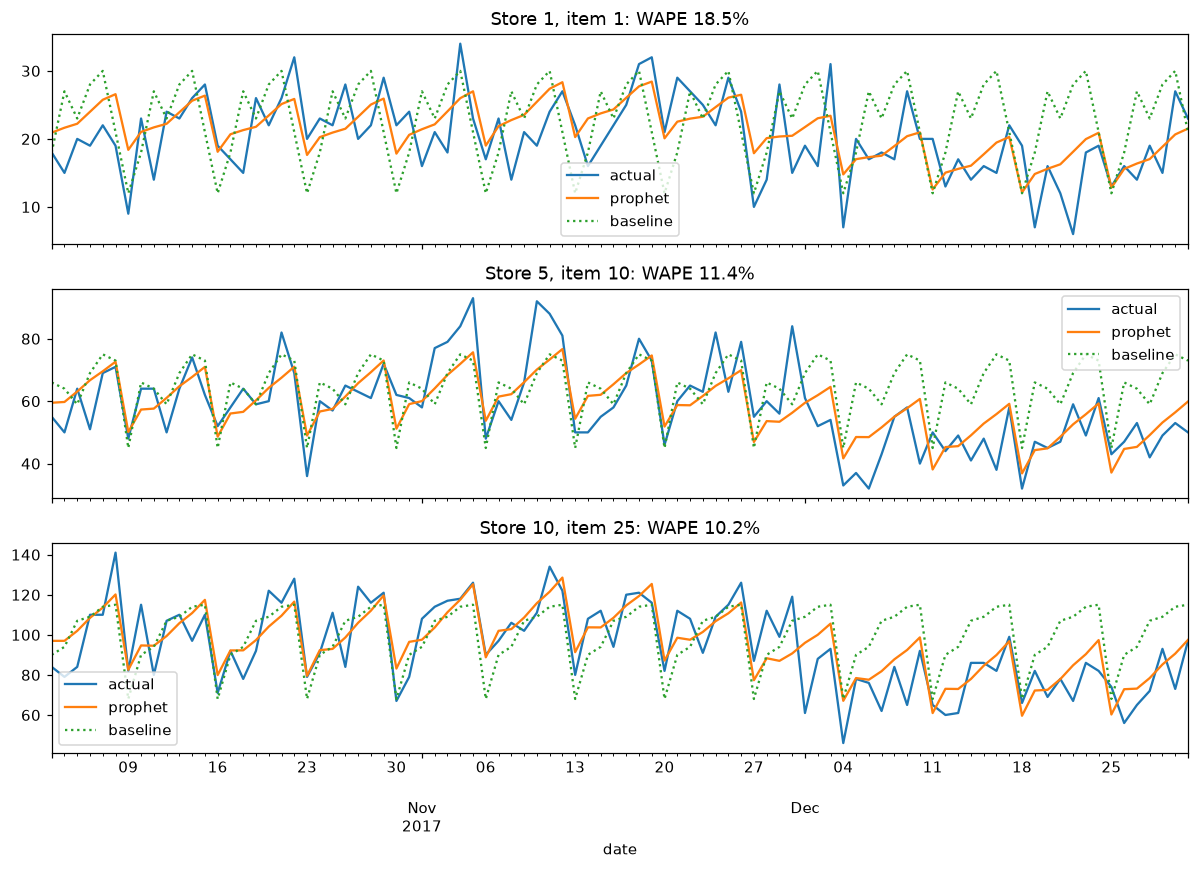

In [4]:
SHOWCASE = [(1, 1), (5, 10), (10, 25)]
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, (store, item) in zip(axes, SHOWCASE):
    g = results[(results.store == store) & (results.item == item)].set_index('date')
    g[['actual', 'prophet', 'baseline']].plot(ax=ax, style=['-', '-', ':'], title=f'Store {store}, item {item}: WAPE {wape(g.actual, g.prophet):.1f}%')
plt.tight_layout()

**Bias by month.** Prophet slightly under-forecasts November's surge and over-forecasts December. That pattern explains the service-level shortfall in notebook 3.

In [5]:
results.assign(error=results.prophet - results.actual).groupby(results.date.dt.strftime('%Y-%m')).error.mean().round(2).rename('mean forecast - actual (units/day)')

date
2017-10    0.74
2017-11   -0.93
2017-12    3.21
Name: mean forecast - actual (units/day), dtype: float64